In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Sales_Data.csv")

In [3]:
df.head()

,Order_ID,Category,Product,Quantity,Unit_Price,Revenue
0,101,Electronics,Laptop,2,50000,100000
1,102,Clothing,Shirt,5,800,4000
2,103,Electronics,Mobile,3,15000,45000
3,104,Furniture,Chair,4,2000,8000
4,105,Clothing,Shoes,2,2500,5000


In [4]:
df.tail()

,Order_ID,Category,Product,Quantity,Unit_Price,Revenue
5,106,Electronics,Headphones,5,1000,5000
6,107,Furniture,Table,2,5000,10000
7,108,Clothing,Jeans,3,1500,4500
8,109,Electronics,Tablet,2,20000,40000
9,110,Furniture,Sofa,1,15000,15000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Order_ID    10 non-null     int64 
 1   Category    10 non-null     object
 2   Product     10 non-null     object
 3   Quantity    10 non-null     int64 
 4   Unit_Price  10 non-null     int64 
 5   Revenue     10 non-null     int64 
dtypes: int64(4), object(2)
memory usage: 612.0+ bytes


In [6]:
print("Shape:", df.shape)

Shape: (10, 6)


In [7]:
df.describe()

,Order_ID,Quantity,Unit_Price,Revenue
count,10.00000,10.00000,10.000000,10.000000
mean,105.50000,2.90000,11280.000000,23650.000000
std,3.02765,1.37032,15336.072219,30744.511705
min,101.00000,1.00000,800.000000,4000.000000
25%,103.25000,2.00000,1625.000000,5000.000000
50%,105.50000,2.50000,3750.000000,9000.000000
75%,107.75000,3.75000,15000.000000,33750.000000
max,110.00000,5.00000,50000.000000,100000.000000


In [8]:
print(df.columns)

Index(['Order_ID', 'Category', 'Product', 'Quantity', 'Unit_Price', 'Revenue'], dtype='object')


In [9]:
print(df.dtypes)

Order_ID       int64
Category      object
Product       object
Quantity       int64
Unit_Price     int64
Revenue        int64
dtype: object


In [10]:
print(df.isnull().sum())

Order_ID      0
Category      0
Product       0
Quantity      0
Unit_Price    0
Revenue       0
dtype: int64


In [11]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Order_ID      0.0
Category      0.0
Product       0.0
Quantity      0.0
Unit_Price    0.0
Revenue       0.0
dtype: float64


In [12]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [13]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [14]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [15]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
Order_ID      0
Category      0
Product       0
Quantity      0
Unit_Price    0
Revenue       0
dtype: int64
Duplicate Records:
0


In [16]:
df.to_csv("Cleaned_Sales_Data.csv", index=False)

In [17]:
print(df["Category"].unique())

['Electronics' 'Clothing' 'Furniture']


In [18]:
category_revenue = df.groupby("Category")["Revenue"].sum()

print(category_revenue)

Category
Clothing        13500
Electronics    190000
Furniture       33000
Name: Revenue, dtype: int64


In [19]:
category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

Category
Electronics    190000
Furniture       33000
Clothing        13500
Name: Revenue, dtype: int64


In [20]:
average_revenue = df.groupby("Category")["Revenue"].mean()

print(average_revenue)

Category
Clothing        4500.0
Electronics    47500.0
Furniture      11000.0
Name: Revenue, dtype: float64


In [21]:
total_quantity = df.groupby("Category")["Quantity"].sum()

print(total_quantity)

Category
Clothing       10
Electronics    12
Furniture       7
Name: Quantity, dtype: int64


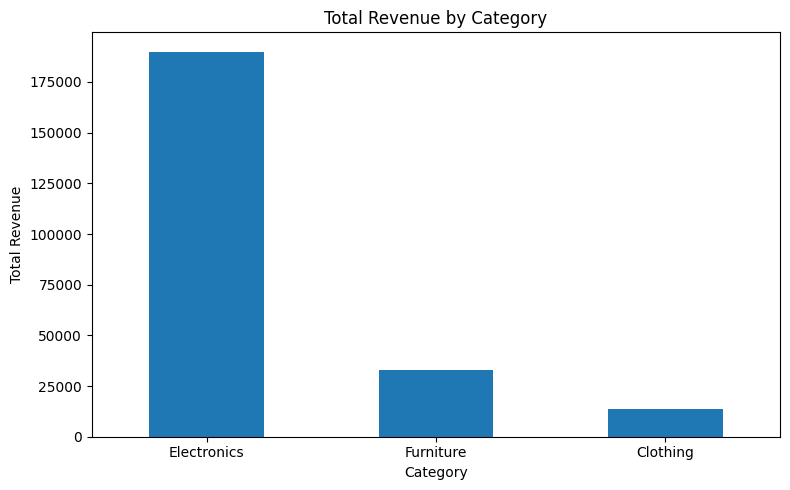

In [22]:
category_revenue.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
df.sort_values(by="Revenue", ascending=False)

,Order_ID,Category,Product,Quantity,Unit_Price,Revenue
0,101,Electronics,Laptop,2,50000,100000
2,103,Electronics,Mobile,3,15000,45000
8,109,Electronics,Tablet,2,20000,40000
9,110,Furniture,Sofa,1,15000,15000
6,107,Furniture,Table,2,5000,10000
3,104,Furniture,Chair,4,2000,8000
4,105,Clothing,Shoes,2,2500,5000
5,106,Electronics,Headphones,5,1000,5000
7,108,Clothing,Jeans,3,1500,4500
1,102,Clothing,Shirt,5,800,4000


In [24]:
sorted_df = df.sort_values(
    by=["Category", "Revenue"],
    ascending=[True, False]
)

print(sorted_df)

   Order_ID     Category     Product  Quantity  Unit_Price  Revenue
4       105     Clothing       Shoes         2        2500     5000
7       108     Clothing       Jeans         3        1500     4500
1       102     Clothing       Shirt         5         800     4000
0       101  Electronics      Laptop         2       50000   100000
2       103  Electronics      Mobile         3       15000    45000
8       109  Electronics      Tablet         2       20000    40000
5       106  Electronics  Headphones         5        1000     5000
9       110    Furniture        Sofa         1       15000    15000
6       107    Furniture       Table         2        5000    10000
3       104    Furniture       Chair         4        2000     8000


In [25]:
sorted_df = df.sort_values(
    by=["Quantity", "Revenue"],
    ascending=[False, False]
)

print(sorted_df)

   Order_ID     Category     Product  Quantity  Unit_Price  Revenue
5       106  Electronics  Headphones         5        1000     5000
1       102     Clothing       Shirt         5         800     4000
3       104    Furniture       Chair         4        2000     8000
2       103  Electronics      Mobile         3       15000    45000
7       108     Clothing       Jeans         3        1500     4500
0       101  Electronics      Laptop         2       50000   100000
8       109  Electronics      Tablet         2       20000    40000
6       107    Furniture       Table         2        5000    10000
4       105     Clothing       Shoes         2        2500     5000
9       110    Furniture        Sofa         1       15000    15000


In [26]:
top_5 = df.sort_values(
    by="Revenue",
    ascending=False
).head(5)

print(top_5)

   Order_ID     Category Product  Quantity  Unit_Price  Revenue
0       101  Electronics  Laptop         2       50000   100000
2       103  Electronics  Mobile         3       15000    45000
8       109  Electronics  Tablet         2       20000    40000
9       110    Furniture    Sofa         1       15000    15000
6       107    Furniture   Table         2        5000    10000


In [27]:
sorted_df.to_csv("Sorted_Sales_Data.csv", index=False)

In [28]:
numeric_df = df.select_dtypes(include=np.number)

In [29]:
correlation_matrix = numeric_df.corr()

print(correlation_matrix)

            Order_ID  Quantity  Unit_Price   Revenue
Order_ID    1.000000 -0.441889   -0.287875 -0.423454
Quantity   -0.441889  1.000000   -0.479121 -0.356965
Unit_Price -0.287875 -0.479121    1.000000  0.972247
Revenue    -0.423454 -0.356965    0.972247  1.000000


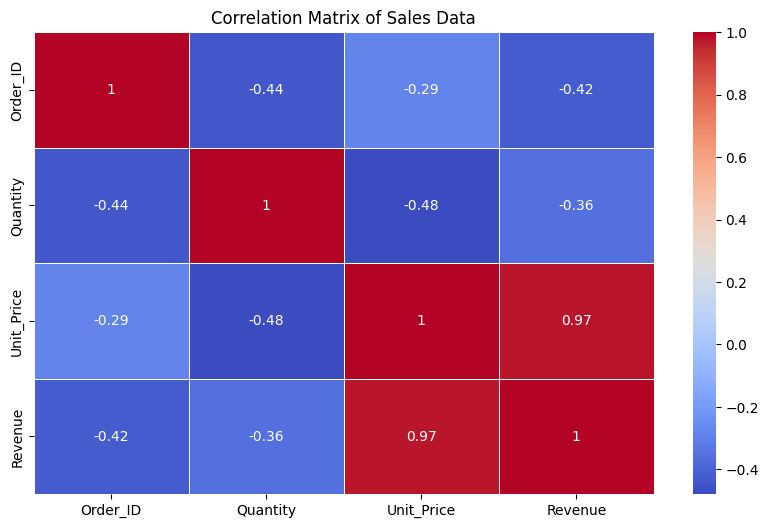

In [30]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Sales Data")

plt.show()